In [6]:
###importing libarires
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
dt=pd.read_excel("/content/drive/MyDrive/test FIN 2/Financial Sample.xlsx")
dt.head()

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Canada,Carretera,NaN,1618.5,3,20,32370.0,0.0,32370.0,16185.0,16185.0,2014-01-01,1,January,2014
1,Government,Germany,Carretera,NaN,1321.0,3,20,26420.0,0.0,26420.0,13210.0,13210.0,2014-01-01,1,January,2014
2,Midmarket,France,Carretera,NaN,2178.0,3,15,32670.0,0.0,32670.0,21780.0,10890.0,2014-06-01,6,June,2014
3,Midmarket,Germany,Carretera,NaN,888.0,3,15,13320.0,0.0,13320.0,8880.0,4440.0,2014-06-01,6,June,2014
4,Midmarket,Mexico,Carretera,NaN,2470.0,3,15,37050.0,0.0,37050.0,24700.0,12350.0,2014-06-01,6,June,2014


**cleaning data**

In [9]:
dt = dt.rename(columns={' Sales': 'Sales'})

In [10]:
dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Segment              700 non-null    object        
 1   Country              700 non-null    object        
 2   Product              700 non-null    object        
 3   Discount Band        647 non-null    object        
 4   Units Sold           700 non-null    float64       
 5   Manufacturing Price  700 non-null    int64         
 6   Sale Price           700 non-null    int64         
 7   Gross Sales          700 non-null    float64       
 8   Discounts            700 non-null    float64       
 9   Sales                700 non-null    float64       
 10  COGS                 700 non-null    float64       
 11  Profit               700 non-null    float64       
 12  Date                 700 non-null    datetime64[ns]
 13  Month Number         700 non-null  

In [11]:
dt.isna().sum()

,0
Segment,0
Country,0
Product,0
Discount Band,53
Units Sold,0
Manufacturing Price,0
Sale Price,0
Gross Sales,0
Discounts,0
Sales,0


*we have 53 null values in discount band column*

In [12]:
continous=dt[['Units Sold','Manufacturing Price','Sale Price','Gross Sales','Discounts','Sales','COGS','Profit']]
continous.head()

,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit
0,1618.5,3,20,32370.0,0.0,32370.0,16185.0,16185.0
1,1321.0,3,20,26420.0,0.0,26420.0,13210.0,13210.0
2,2178.0,3,15,32670.0,0.0,32670.0,21780.0,10890.0
3,888.0,3,15,13320.0,0.0,13320.0,8880.0,4440.0
4,2470.0,3,15,37050.0,0.0,37050.0,24700.0,12350.0


In [13]:
continous.describe().round(2)

,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit
count,700.00,700.00,700.00,700.00,700.00,700.00,700.00,700.00
mean,1608.29,96.48,118.43,182759.43,13150.35,169609.07,145475.21,24133.86
std,867.43,108.60,136.78,254262.28,22962.93,236726.35,203865.51,42760.63
min,200.00,3.00,7.00,1799.00,0.00,1655.08,918.00,-40617.50
25%,905.00,5.00,12.00,17391.75,800.32,15928.00,7490.00,2805.96
50%,1542.50,10.00,20.00,37980.00,2585.25,35540.20,22506.25,9242.20
75%,2229.12,250.00,300.00,279025.00,15956.34,261077.50,245607.50,22662.00
max,4492.50,260.00,350.00,1207500.00,149677.50,1159200.00,950625.00,262200.00


### finding outliers

<Axes: xlabel='Units Sold', ylabel='Count'>

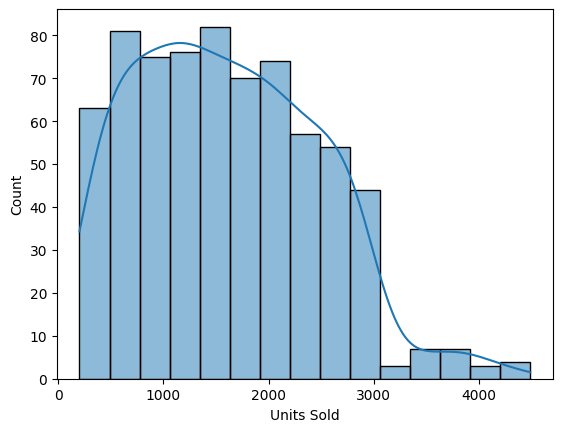

In [14]:
sns.histplot(data=dt,x='Units Sold', kde=True)

<Axes: xlabel='Gross Sales'>

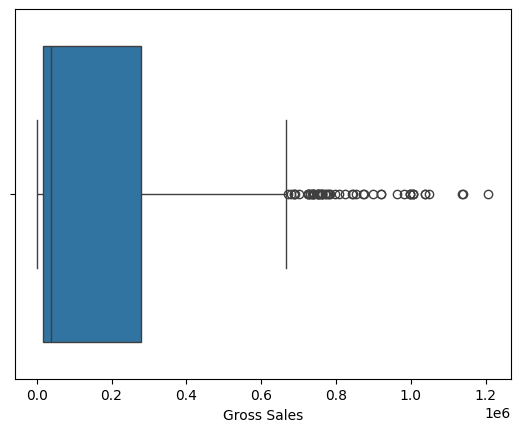

In [15]:
sns.boxplot(data=dt,x='Gross Sales')

<Axes: xlabel='Discounts'>

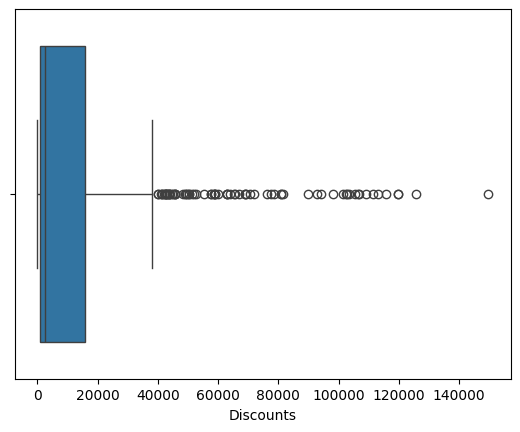

In [16]:
sns.boxplot(data=dt,x='Discounts')

<Axes: xlabel='Sales'>

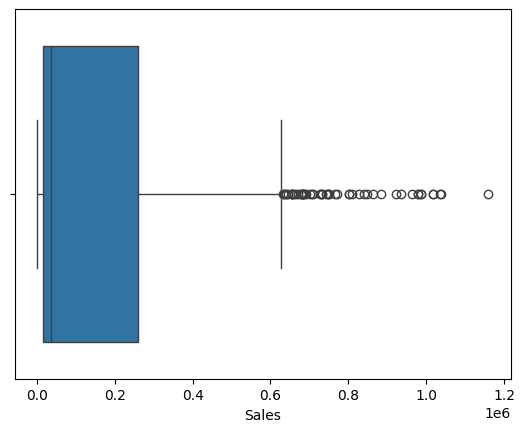

In [17]:
sns.boxplot(data=dt,x='Sales')

In [18]:
dt[['Gross Sales','Discounts','Sales']]

,Gross Sales,Discounts,Sales
0,32370.0,0.00,32370.00
1,26420.0,0.00,26420.00
2,32670.0,0.00,32670.00
3,13320.0,0.00,13320.00
4,37050.0,0.00,37050.00
...,...,...,...
695,742500.0,111375.00,631125.00
696,163800.0,24570.00,139230.00
697,9576.0,1436.40,8139.60
698,5061.0,759.15,4301.85


In [19]:
q1=dt['Sales'].quantile(0.25)
q2=dt['Sales'].quantile(0.50)
q3=dt['Sales'].quantile(0.75)
iqr=q3-q1
print('iqr=',iqr)
print(q1,q2,q3)

iqr= 245149.5
15928.0 35540.2 261077.5


In [20]:
lb=iqr-(1.5*iqr)
ub=iqr+(1.5*iqr)
print('lower boundry=',lb)
print('ubber boundry=',ub)

lower boundry= -122574.75
ubber boundry= 612873.75


In [21]:
dt[dt.Sales > ub].shape[0]

56

In [22]:
print('outliers upper boundry=',dt[dt.Sales > ub].shape[0],'rows')

outliers upper boundry= 56 rows


In [23]:
px.box(dt,x='Sales')

In [24]:
dt[dt.Sales==1159200.00]

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
192,Government,United States of America,Paseo,Low,3450.0,10,350,1207500.0,48300.0,1159200.0,897000.0,262200.0,2014-07-01,7,July,2014


In [25]:
outliers=dt[dt.Sales > ub]
outliers.shape

(56, 16)

In [26]:
clean_dt=dt[dt.Sales < ub]
clean_dt.head()

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Canada,Carretera,NaN,1618.5,3,20,32370.0,0.0,32370.0,16185.0,16185.0,2014-01-01,1,January,2014
1,Government,Germany,Carretera,NaN,1321.0,3,20,26420.0,0.0,26420.0,13210.0,13210.0,2014-01-01,1,January,2014
2,Midmarket,France,Carretera,NaN,2178.0,3,15,32670.0,0.0,32670.0,21780.0,10890.0,2014-06-01,6,June,2014
3,Midmarket,Germany,Carretera,NaN,888.0,3,15,13320.0,0.0,13320.0,8880.0,4440.0,2014-06-01,6,June,2014
4,Midmarket,Mexico,Carretera,NaN,2470.0,3,15,37050.0,0.0,37050.0,24700.0,12350.0,2014-06-01,6,June,2014


### univarite analysis

<Axes: xlabel='Segment', ylabel='count'>

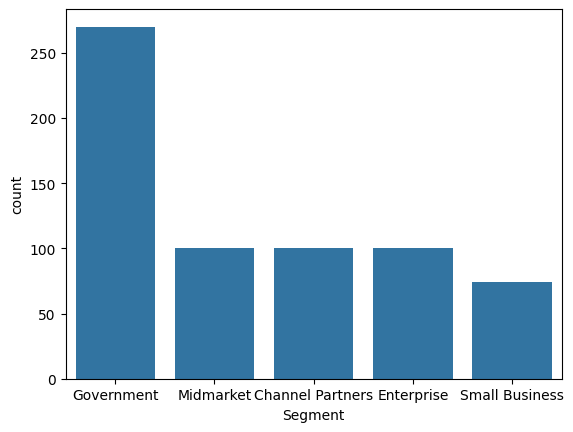

In [27]:
sns.countplot(data=clean_dt,x='Segment')

<Axes: xlabel='Country', ylabel='count'>

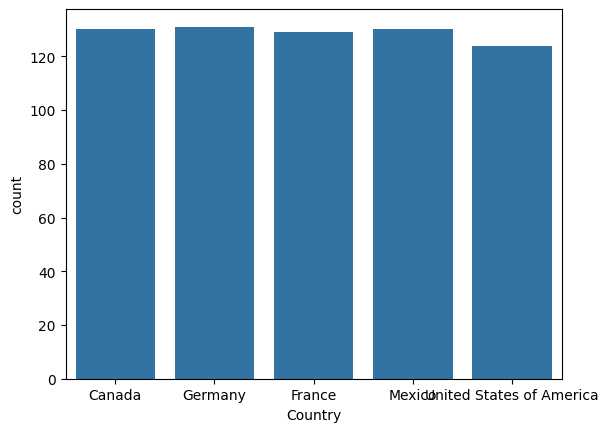

In [28]:
sns.countplot(data=clean_dt,x='Country')

<Axes: xlabel='Product', ylabel='count'>

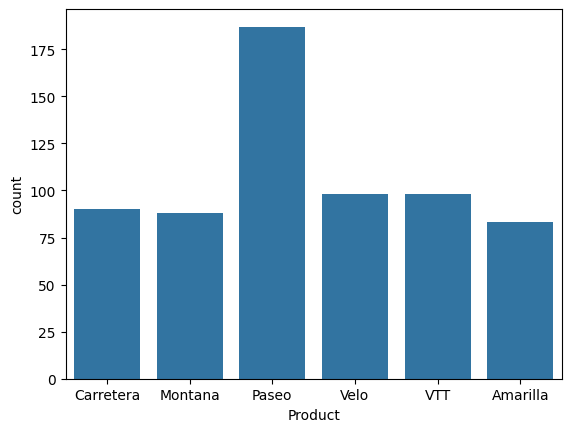

In [29]:
sns.countplot(data=clean_dt,x='Product')

<Axes: xlabel='Discount Band', ylabel='count'>

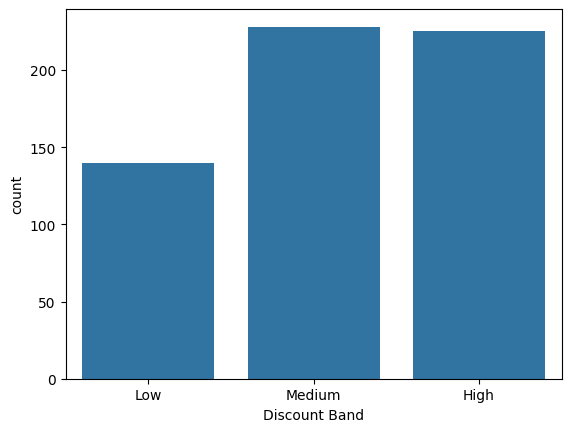

In [30]:
sns.countplot(data=clean_dt,x='Discount Band')

<Axes: xlabel='Month Name', ylabel='count'>

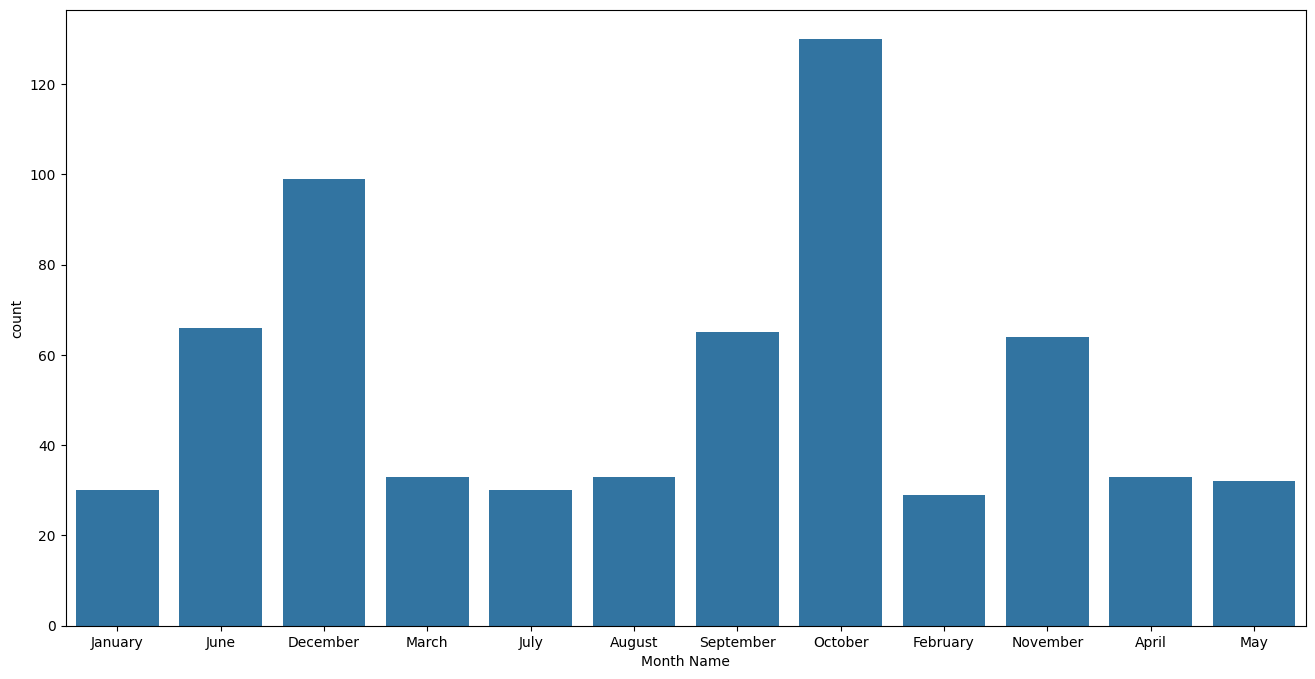

In [31]:
plt.figure(figsize=(16,8))
sns.countplot(data=clean_dt,x='Month Name')

In [32]:
clean_dt.head(1)

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Canada,Carretera,NaN,1618.5,3,20,32370.0,0.0,32370.0,16185.0,16185.0,2014-01-01,1,January,2014


In [33]:
clean_dt.Year.value_counts()

,count
Year,
2014,483
2013,161


<Axes: xlabel='Year', ylabel='count'>

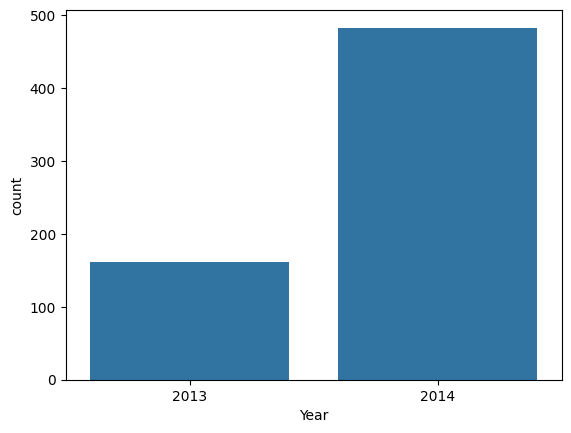

In [34]:
sns.countplot(data=clean_dt,x='Year')

### bivariate analysis

In [35]:
seg_prof=clean_dt.groupby(['Segment'])['Profit'].sum()

In [36]:
px.bar(seg_prof)


In [37]:
Enterprisen=clean_dt[clean_dt.Segment=='Enterprise']
Enterprisen.head(1)

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
11,Enterprise,Canada,Montana,NaN,2665.5,5,125,333187.5,0.0,333187.5,319860.0,13327.5,2014-07-01,7,July,2014


In [38]:
seg_prof

,Profit
Segment,
Channel Partners,1316803.140
Enterprise,-614545.625
Government,6386893.920
Midmarket,660103.075
Small Business,2403300.000


In [39]:
negative_profit=clean_dt[clean_dt.Profit < 0]
negative_profit.head()


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
232,Enterprise,United States of America,Montana,Medium,3627.0,5,125,453375.0,22668.75,430706.25,435240.0,-4533.75,2014-07-01,7,July,2014
237,Enterprise,United States of America,Paseo,Medium,2992.0,10,125,374000.0,18700.00,355300.00,359040.0,-3740.00,2014-03-01,3,March,2014
238,Enterprise,France,Paseo,Medium,2385.0,10,125,298125.0,14906.25,283218.75,286200.0,-2981.25,2014-03-01,3,March,2014
246,Enterprise,United States of America,Paseo,Medium,861.0,10,125,107625.0,5381.25,102243.75,103320.0,-1076.25,2014-10-01,10,October,2014
247,Enterprise,France,Paseo,Medium,704.0,10,125,88000.0,4400.00,83600.00,84480.0,-880.00,2013-10-01,10,October,2013


**#### we have 58 columns with negative profit in enterprise
**

In [40]:
Country_prof=clean_dt.groupby(['Country'])['Profit'].sum()
px.bar(Country_prof,text_auto='.2s')


**germany makes highest profit**

In [41]:
Country_sales=clean_dt.groupby(['Country'])['Sales'].sum()
px.bar(Country_sales,text_auto='.2s')


canada makes the highest sales but not highest profit

In [42]:
Product_prof=clean_dt.groupby(['Product'])['Profit'].sum()
px.bar(Product_prof,text_auto='.2s')


paseo makes the highest profit


In [43]:
Product_sales=clean_dt.groupby(['Product'])['Sales'].sum()
px.bar(Product_sales,text_auto='.2s')


paseeo makes the highest sales & profit

In [44]:
month_prof=clean_dt.groupby(['Month Name'])['Profit'].sum()
px.bar(month_prof,text_auto='.2s')


october makes the highest profit

In [45]:
month_sales=clean_dt.groupby(['Month Name'])['Sales'].sum()
px.bar(month_sales,text_auto='.2s')

october makes the highest profit & sales

In [46]:

Year_prof=clean_dt.groupby(['Year'])['Profit'].sum()
px.bar(Year_prof,text_auto='.2s')

In [47]:
Discount_prof=clean_dt.groupby(['Discount Band'])['Profit'].sum()
px.bar(Discount_prof,text_auto='.2s')

medium discount makes highest profit

In [48]:
iscount_prof=clean_dt.groupby(['Discount Band'])['Sales'].sum()
px.bar(Discount_prof,text_auto='.2s')

In [49]:
clean_dt.head()

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Canada,Carretera,NaN,1618.5,3,20,32370.0,0.0,32370.0,16185.0,16185.0,2014-01-01,1,January,2014
1,Government,Germany,Carretera,NaN,1321.0,3,20,26420.0,0.0,26420.0,13210.0,13210.0,2014-01-01,1,January,2014
2,Midmarket,France,Carretera,NaN,2178.0,3,15,32670.0,0.0,32670.0,21780.0,10890.0,2014-06-01,6,June,2014
3,Midmarket,Germany,Carretera,NaN,888.0,3,15,13320.0,0.0,13320.0,8880.0,4440.0,2014-06-01,6,June,2014
4,Midmarket,Mexico,Carretera,NaN,2470.0,3,15,37050.0,0.0,37050.0,24700.0,12350.0,2014-06-01,6,June,2014


### multivariate Analysis


<Axes: xlabel='Segment'>

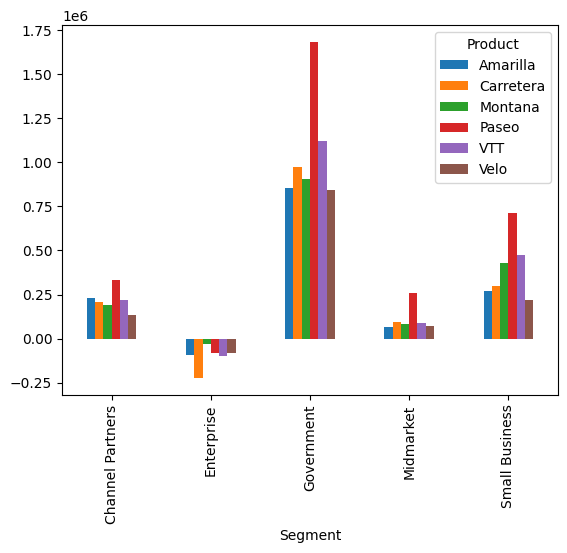

In [50]:
z=clean_dt.groupby(['Segment','Product'])['Profit'].sum()
z.unstack().plot(kind='bar')



<Axes: xlabel='Country'>

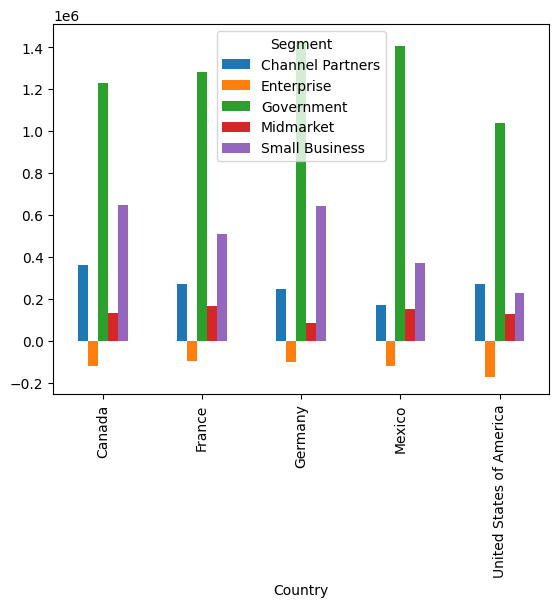

In [51]:
x=clean_dt.groupby(['Country','Segment'])['Profit'].sum()
x.unstack().plot(kind='bar')


<Axes: xlabel='Country'>

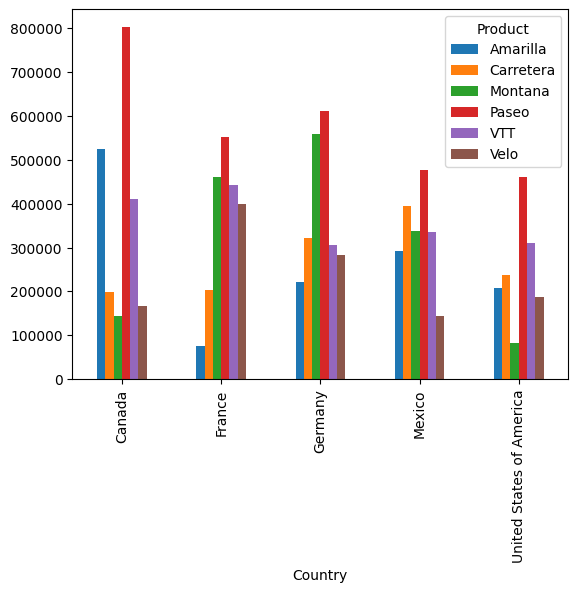

In [52]:
x=clean_dt.groupby(['Country','Product'])['Profit'].sum()
x.unstack().plot(kind='bar')

<Axes: xlabel='Country'>

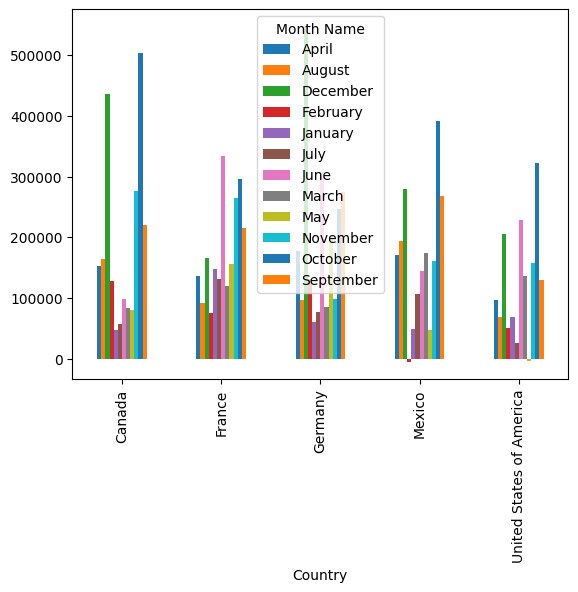

In [53]:
x=clean_dt.groupby(['Country','Month Name'])['Profit'].sum()
x.unstack().plot(kind='bar')
